In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
#for dirname, _, filenames in os.walk('/kaggle/input'):
 #   for filename in filenames:
  #      print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
%pip install -q ultralytics

Note: you may need to restart the kernel to use updated packages.


In [3]:
import hashlib
import random
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

# ---------- General ----------
SEED = 42
WORKERS = 4
OUTPUT_DIR = Path("/kaggle/working")

# ---------- Source 1: skin diseases (folder name -> label) ----------
SKIN_ROOT = Path("/kaggle/input/datasets/ascanipek/skin-diseases/kaggle")
SKIN_SPLITS = ("train", "val", "test")  # original splits are merged, then re-split at the end
SKIN_CLASSES = {
    "1. Enfeksiyonel": "Enfeksiyonel",
    "2. Ekzama": "Ekzama",
    "3. Akne": "Akne",
}
MIN_SIDE = 100  # drop skin-disease images whose shorter side is below this

# ---------- Source 2: healthy / vitiligo ----------
VITILIGO_ROOT = Path(
    "/kaggle/input/datasets/rajeebpramanik/"
    "vitiligo-dataset-healthy-and-vitiligo/merge-vitiligo"
)
VITILIGO_CLASSES = ("Healthy", "Vitiligo")

# ---------- Source 3: non-skin negatives ----------
IMAGENET_ROOT = Path("/kaggle/input/datasets/lijiyu/imagenet/imagenet")
NON_SKIN_SAMPLE_SIZE = 5000
PERSON_CLASS_ID = 0      # "person" in COCO
PERSON_CONFIDENCE = 0.25

# ---------- Split ----------
VAL_FRACTION = 0.10
TEST_FRACTION = 0.10

In [4]:
def list_images(folders):
    """DataFrame(path, label) of every file under each (directory, label) pair."""
    rows = [
        (str(p), label)
        for directory, label in folders
        for p in sorted(directory.rglob("*"))
        if p.is_file()
    ]
    return pd.DataFrame(rows, columns=["path", "label"])


def fingerprint(path):
    """Size, MD5 of the file bytes, and a 64-bit dHash. Returns None if unreadable."""
    try:
        with Image.open(path) as im:
            width, height = im.size
            gray = np.asarray(
                im.convert("L").resize((9, 8), Image.Resampling.LANCZOS), dtype=np.int16
            )
        bits = (gray[:, 1:] > gray[:, :-1]).flatten()
        return {
            "path": path,
            "md5": hashlib.md5(Path(path).read_bytes()).hexdigest(),
            "dhash": np.packbits(bits).tobytes().hex(),
            "width": width,
            "height": height,
        }
    except Exception:
        return None


def add_fingerprints(df):
    """Attach fingerprint columns to df; unreadable images are dropped."""
    with ThreadPoolExecutor(max_workers=WORKERS) as pool:
        results = list(tqdm(pool.map(fingerprint, df["path"]), total=len(df), desc="Fingerprinting"))
    readable = pd.DataFrame([r for r in results if r is not None])
    print(f"  unreadable images dropped: {len(df) - len(readable):,}")
    return df.merge(readable, on="path")


def assign_groups(df, keys):
    """Group id per row; rows sharing a value in ANY of `keys` end up in the same group."""
    n = len(df)
    idx = np.arange(n)
    src, dst = [], []
    for key in keys:
        first_row = pd.Series(idx).groupby(df[key].to_numpy()).transform("first").to_numpy()
        src.append(idx)
        dst.append(first_row)
    src, dst = np.concatenate(src), np.concatenate(dst)
    graph = coo_matrix((np.ones(len(src)), (src, dst)), shape=(n, n))
    return connected_components(graph, directed=False)[1]


def deduplicate(df, keys):
    """
    Collapse duplicate groups to one image each.
    Groups containing more than one label are quarantined instead of kept.
    Returns (unique_df, quarantined_df).
    """
    df = df.copy()
    df["group_id"] = assign_groups(df, keys)

    conflicting = df.groupby("group_id")["label"].transform("nunique") > 1
    quarantined = df[conflicting].sort_values(["group_id", "path"])
    unique = (
        df[~conflicting]
        .sort_values("path")
        .drop_duplicates("group_id")
        .drop(columns="group_id")
        .reset_index(drop=True)
    )
    print(f"  {len(df):,} images -> {len(unique):,} unique | {len(quarantined):,} quarantined (label conflict)")
    return unique, quarantined


def stratified_split(df):
    """Stratified train/val/test split; returns df with a `split` column."""
    train, rest = train_test_split(
        df, test_size=VAL_FRACTION + TEST_FRACTION, random_state=SEED, stratify=df["label"]
    )
    val, test = train_test_split(
        rest,
        test_size=TEST_FRACTION / (VAL_FRACTION + TEST_FRACTION),
        random_state=SEED,
        stratify=rest["label"],
    )
    return pd.concat(
        [train.assign(split="train"), val.assign(split="val"), test.assign(split="test")],
        ignore_index=True,
    )


def split_summary(df):
    counts = pd.crosstab(df["label"], df["split"]).reindex(columns=["train", "val", "test"], fill_value=0)
    counts["total"] = counts.sum(axis=1)
    print(counts.to_string())
    print(f"\nTotal: {len(df):,}")

In [5]:
def load_skin_diseases():
    folders = [
        (SKIN_ROOT / split / folder, label)
        for split in SKIN_SPLITS
        for folder, label in SKIN_CLASSES.items()
    ]
    df = add_fingerprints(list_images(folders))
    df = df[df[["width", "height"]].min(axis=1) >= MIN_SIDE]
    return deduplicate(df, keys=["md5", "dhash"])  # near-duplicates matter here (cross-split leakage)


def load_vitiligo():
    df = add_fingerprints(list_images([(VITILIGO_ROOT / name, name) for name in VITILIGO_CLASSES]))
    return deduplicate(df, keys=["md5"])


print("Skin diseases:")
skin, skin_quarantine = load_skin_diseases()
print("Healthy / Vitiligo:")
vitiligo, vitiligo_quarantine = load_vitiligo()

print("Cross-source check:")
data, cross_quarantine = deduplicate(pd.concat([skin, vitiligo], ignore_index=True), keys=["md5"])

quarantine = (
    pd.concat(
        {"skin": skin_quarantine, "vitiligo": vitiligo_quarantine, "cross_source": cross_quarantine},
        names=["stage"],
    )
    .reset_index(level="stage")
    .reset_index(drop=True)
)
quarantine.to_csv(OUTPUT_DIR / "skin_quarantine_review.csv", index=False)

print("\nImages per class:")
print(data["label"].value_counts().to_string())
print("\nImage size per class:")
print(data.groupby("label")[["width", "height"]].agg(["min", "median", "max"]).to_string())

Skin diseases:


Fingerprinting:   0%|          | 0/15381 [00:00<?, ?it/s]

  unreadable images dropped: 0
  15,381 images -> 9,274 unique | 164 quarantined (label conflict)
Healthy / Vitiligo:


Fingerprinting:   0%|          | 0/15926 [00:00<?, ?it/s]

  unreadable images dropped: 0
  15,926 images -> 15,809 unique | 0 quarantined (label conflict)
Cross-source check:
  25,083 images -> 25,083 unique | 0 quarantined (label conflict)

Images per class:
label
Vitiligo        10154
Healthy          5655
Enfeksiyonel     4129
Ekzama           2710
Akne             2435

Image size per class:
             width              height             
               min median   max    min median   max
label                                              
Akne           100  651.0  5573    100  474.0  4028
Ekzama         294  594.0   720    222  472.0  1080
Enfeksiyonel   294  720.0   720    222  476.0  1128
Healthy        207  640.0  1600    204  640.0  1200
Vitiligo        80  640.0  8688     29  640.0  5792


In [6]:
def sample_non_skin():
    from ultralytics import YOLO

    paths = sorted(
        str(p) for split in ("train", "val") for p in (IMAGENET_ROOT / split).rglob("*") if p.is_file()
    )
    sample = random.Random(SEED).sample(paths, min(NON_SKIN_SAMPLE_SIZE, len(paths)))

    detector = YOLO("yolov8n.pt")
    BATCH = 32
    no_person = []

    for i in tqdm(range(0, len(sample), BATCH), desc="Person filter"):
        chunk = sample[i : i + BATCH]
        results = detector.predict(
            source=chunk,
            classes=[PERSON_CLASS_ID],
            conf=PERSON_CONFIDENCE,
            imgsz=640,
            batch=BATCH,
            verbose=False,
        )
        no_person.extend(r.path for r in results if len(r.boxes) == 0)

    print(f"  sampled {len(sample):,} | kept {len(no_person):,} | removed (person detected) {len(sample) - len(no_person):,}")
    return pd.DataFrame({"path": no_person, "label": "Non-Skin"})


non_skin = sample_non_skin()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Person filter:   0%|          | 0/157 [00:00<?, ?it/s]

  sampled 5,000 | kept 3,824 | removed (person detected) 1,176


In [7]:
final_df = stratified_split(
    pd.concat([data[["path", "label"]], non_skin], ignore_index=True)
)
final_df.to_csv(OUTPUT_DIR / "dataset_split.csv", index=False)

split_summary(final_df)

split         train   val  test  total
label                                 
Akne           1948   243   244   2435
Ekzama         2168   271   271   2710
Enfeksiyonel   3303   413   413   4129
Healthy        4524   565   566   5655
Non-Skin       3059   383   382   3824
Vitiligo       8123  1016  1015  10154

Total: 28,907


In [8]:
import json
import math

import cv2
from PIL import Image, ImageEnhance, ImageOps

DROP_CLASSES = ["Enfeksiyonel"]

df = final_df[~final_df["label"].isin(DROP_CLASSES)].reset_index(drop=True)
print("After removing", DROP_CLASSES)
split_summary(df)

After removing ['Enfeksiyonel']
split     train   val  test  total
label                             
Akne       1948   243   244   2435
Ekzama     2168   271   271   2710
Healthy    4524   565   566   5655
Non-Skin   3059   383   382   3824
Vitiligo   8123  1016  1015  10154

Total: 24,778


In [9]:
IMG_SIZE = 224
TARGET_TRAIN_PER_CLASS = 3000        # train classes above this are undersampled, below are oversampled
PAD_COLOR = (124, 116, 104)          # ~ImageNet mean, so padding is neutral after normalization
CLAHE_CLIP = 2.0
CLAHE_GRID = (8, 8)
AUG_MAX_ROTATION = 25                # degrees
AUG_ZOOM_RANGE = (1.0, 1.2)
AUG_BRIGHTNESS = (0.85, 1.15)
AUG_CONTRAST = (0.85, 1.15)
PROCESSED_DIR = OUTPUT_DIR / "processed"

In [10]:
MAX_PER_CLASS = 2100
MIN_PER_CLASS = None   # optional: e.g. 2000 to top up smaller classes with augmented copies


def balance_train(df, max_per_class, min_per_class=None):
    """Cap train classes at max_per_class. If min_per_class is set, smaller classes are
    topped up to that size with augmented copies (aug_id >= 1)."""
    rng = np.random.default_rng(SEED)
    parts = []
    for label, g in df[df["split"] == "train"].groupby("label"):
        if len(g) > max_per_class:
            parts.append(g.sample(max_per_class, random_state=SEED).assign(aug_id=0))
        elif min_per_class and len(g) < min_per_class:
            extra = min_per_class - len(g)
            rounds = math.ceil(extra / len(g))
            picks = np.concatenate([rng.permutation(len(g)) for _ in range(rounds)])[:extra]
            copies = g.iloc[picks].copy()
            copies["aug_id"] = copies.groupby("path").cumcount() + 1
            parts.append(pd.concat([g.assign(aug_id=0), copies]))
        else:
            parts.append(g.assign(aug_id=0))

    others = df[df["split"] != "train"].assign(aug_id=0)
    out = pd.concat(parts + [others], ignore_index=True)

    key = out["path"].map(lambda p: hashlib.md5(p.encode()).hexdigest()[:16])
    out["out_path"] = [
        str(PROCESSED_DIR / s / l / f"{k}_{a}.png")
        for s, l, k, a in zip(out["split"], out["label"], key, out["aug_id"])
    ]
    return out


plan = balance_train(df, MAX_PER_CLASS, MIN_PER_CLASS)
print(pd.crosstab(plan["label"], plan["split"]).reindex(columns=["train", "val", "test"]).to_string())
print("\nSynthetic train images per class:")
print(plan[plan["aug_id"] > 0].groupby("label").size().to_string() or "none")

split     train   val  test
label                      
Akne       1948   243   244
Ekzama     2100   271   271
Healthy    2100   565   566
Non-Skin   2100   383   382
Vitiligo   2100  1016  1015

Synthetic train images per class:
Series([], )


In [11]:
def resize_keep_aspect(im, size):
    w, h = im.size
    scale = size / max(w, h)
    new = (max(1, round(w * scale)), max(1, round(h * scale)))
    return im.resize(new, Image.Resampling.LANCZOS)


def apply_clahe(im):
    """Contrast-limited adaptive histogram equalization on lightness only (hue/saturation untouched)."""
    lab = cv2.cvtColor(np.asarray(im), cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=CLAHE_CLIP, tileGridSize=CLAHE_GRID).apply(lab[..., 0])
    return Image.fromarray(cv2.cvtColor(lab, cv2.COLOR_LAB2RGB))


def letterbox(im, size):
    canvas = Image.new("RGB", (size, size), PAD_COLOR)
    canvas.paste(im, ((size - im.width) // 2, (size - im.height) // 2))
    return canvas


def process_row(row):
    """Returns (out_path, channel_sum, channel_sumsq, n_pixels) for train rows; None on failure."""
    try:
        out = Path(row.out_path)
        out.parent.mkdir(parents=True, exist_ok=True)

        with Image.open(row.path) as im:
            im = ImageOps.exif_transpose(im)      # fix phone-camera rotation
            im = im.convert("RGB")                # handles grayscale / RGBA / palette images
            im = resize_keep_aspect(im, IMG_SIZE) # no stretching
            im = apply_clahe(im)
            im = letterbox(im, IMG_SIZE)          # fixed IMG_SIZE x IMG_SIZE

        im.save(out, format="PNG")

        if row.split == "train":
            a = np.asarray(im, dtype=np.float64) / 255.0
            return row.out_path, a.sum((0, 1)), (a ** 2).sum((0, 1)), a.shape[0] * a.shape[1]
        return row.out_path, None, None, 0
    except Exception as e:
        print(f"failed: {row.path} ({e})")
        return None


rows = list(plan.itertuples(index=False))
with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    results = list(tqdm(pool.map(process_row, rows), total=len(rows), desc="Preprocessing"))

ok = {r[0] for r in results if r is not None}
processed = plan[plan["out_path"].isin(ok)].reset_index(drop=True)
print(f"processed {len(processed):,} / {len(plan):,} images")

Preprocessing:   0%|          | 0/15304 [00:00<?, ?it/s]

processed 15,304 / 15,304 images


In [12]:
train_stats = [r for r in results if r is not None and r[1] is not None]
n_pix = sum(r[3] for r in train_stats)
mean = sum(r[1] for r in train_stats) / n_pix
std = np.sqrt(sum(r[2] for r in train_stats) / n_pix - mean ** 2)

class_names = sorted(processed["label"].unique())
meta = {
    "img_size": IMG_SIZE,
    "mean": mean.tolist(),
    "std": std.tolist(),
    "class_to_idx": {c: i for i, c in enumerate(class_names)},
}
(OUTPUT_DIR / "preprocessing_meta.json").write_text(json.dumps(meta, indent=2))
processed.to_csv(OUTPUT_DIR / "processed_dataset_split.csv", index=False)

print("mean:", np.round(mean, 4), "| std:", np.round(std, 4))
print("classes:", meta["class_to_idx"])
print("\nFinal processed dataset:")
print(pd.crosstab(processed["label"], processed["split"]).reindex(columns=["train", "val", "test"]).to_string())

mean: [     0.6152      0.5221      0.4751] | std: [     0.2664      0.2559      0.2668]
classes: {'Akne': 0, 'Ekzama': 1, 'Healthy': 2, 'Non-Skin': 3, 'Vitiligo': 4}

Final processed dataset:
split     train   val  test
label                      
Akne       1948   243   244
Ekzama     2100   271   271
Healthy    2100   565   566
Non-Skin   2100   383   382
Vitiligo   2100  1016  1015


In [13]:
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SPLITS = ["train", "val", "test"]
LABELS = sorted(processed["label"].unique())
rng_vis = np.random.default_rng(SEED)

In [14]:
summary = pd.DataFrame({
    "step": [
        "Skin diseases: after dedup + min-side filter",
        "Vitiligo/Healthy: after dedup",
        "Non-skin: after person filter",
        "Quarantined (label conflicts)",
        "Merged dataset (before class removal)",
        f"After removing {DROP_CLASSES}",
        "After train cap (processed)",
    ],
    "images": [
        len(skin), len(vitiligo), len(non_skin), len(quarantine),
        len(final_df), len(df), len(processed),
    ],
})
print(summary.to_string(index=False))

                                        step  images
Skin diseases: after dedup + min-side filter    9274
               Vitiligo/Healthy: after dedup   15809
               Non-skin: after person filter    3824
               Quarantined (label conflicts)     164
       Merged dataset (before class removal)   28907
             After removing ['Enfeksiyonel']   24778
                 After train cap (processed)   15304


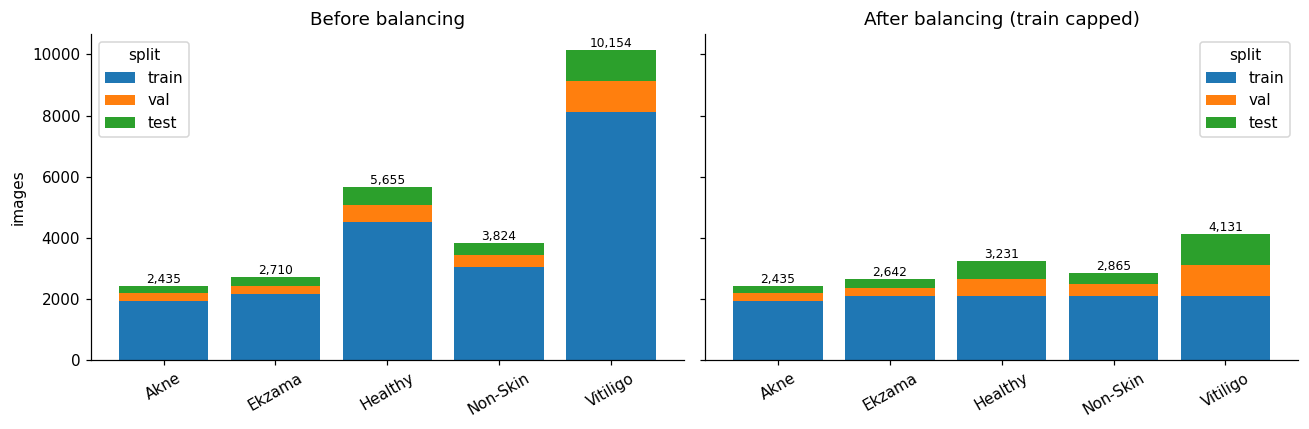

Train images per class after balancing:
label
Akne        1948
Ekzama      2100
Healthy     2100
Non-Skin    2100
Vitiligo    2100
smallest/largest class ratio: 0.93


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, frame, title in zip(axes, [df, processed], ["Before balancing", "After balancing (train capped)"]):
    ct = pd.crosstab(frame["label"], frame["split"]).reindex(index=LABELS, columns=SPLITS, fill_value=0)
    ct.plot(kind="bar", stacked=True, ax=ax, width=0.8)
    for i, total in enumerate(ct.sum(axis=1)):
        ax.text(i, total, f"{total:,}", ha="center", va="bottom", fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("images")
plt.tight_layout()
plt.show()

train_ct = processed[processed["split"] == "train"]["label"].value_counts().reindex(LABELS)
print("Train images per class after balancing:")
print(train_ct.to_string())
print(f"smallest/largest class ratio: {train_ct.min() / train_ct.max():.2f}")

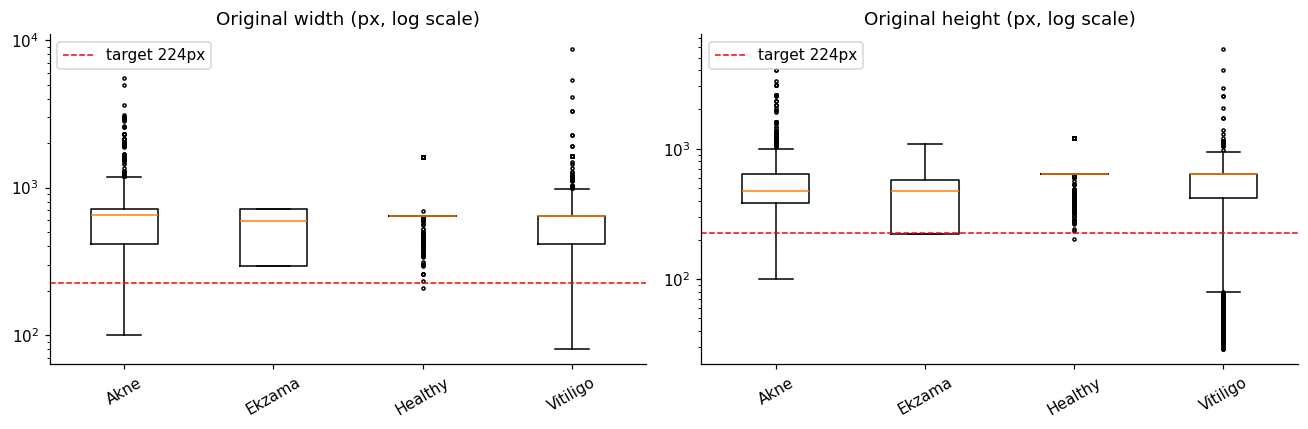

(Non-Skin sizes were not stored in the notebook, so it is not shown here.)


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
size_df = data[data["label"].isin(LABELS)]
for ax, col in zip(axes, ["width", "height"]):
    groups = [size_df.loc[size_df["label"] == l, col] for l in LABELS if (size_df["label"] == l).any()]
    names = [l for l in LABELS if (size_df["label"] == l).any()]
    ax.boxplot(groups, tick_labels=names, showfliers=True, flierprops={"markersize": 2})
    ax.axhline(IMG_SIZE, color="red", ls="--", lw=1, label=f"target {IMG_SIZE}px")
    ax.set_yscale("log")
    ax.set_title(f"Original {col} (px, log scale)")
    ax.tick_params(axis="x", rotation=30)
    ax.legend()
plt.tight_layout()
plt.show()
print("(Non-Skin sizes were not stored in the notebook, so it is not shown here.)")

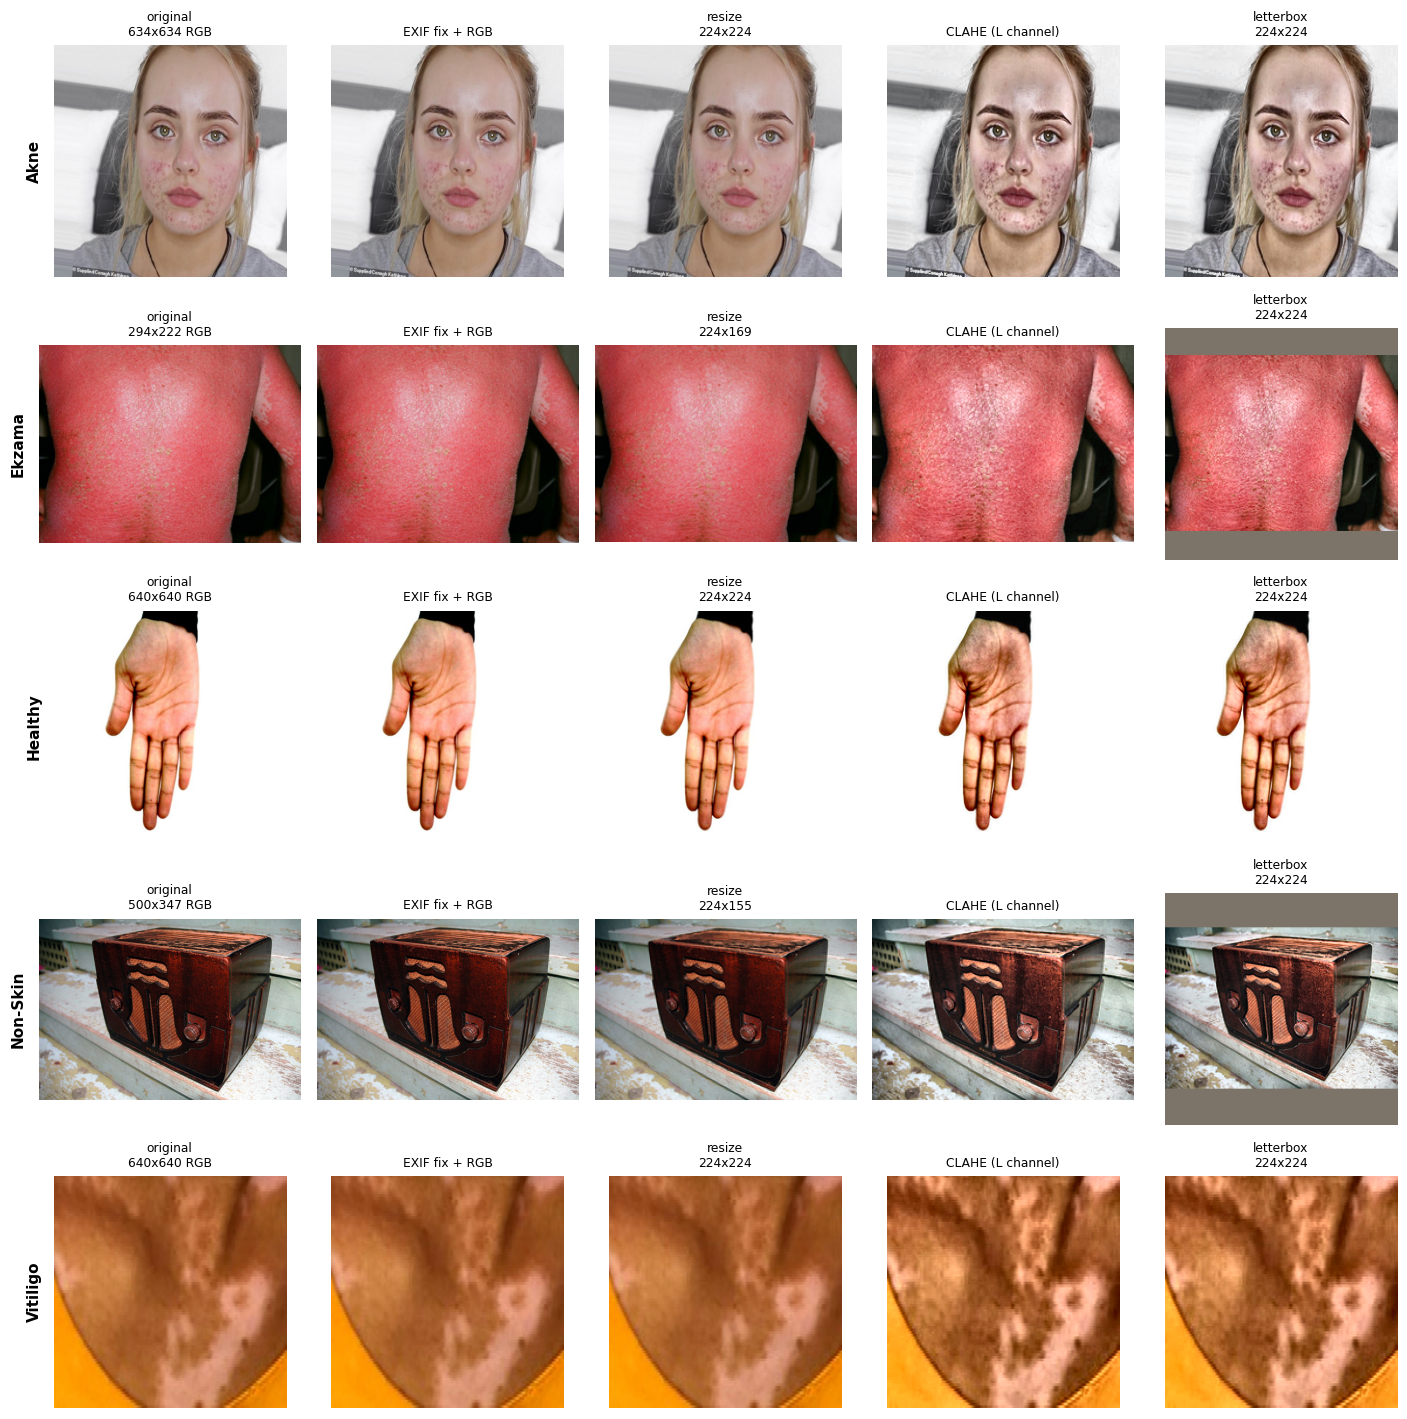

In [23]:
def pipeline_stages(path):
    with Image.open(path) as im:
        raw = im.copy()
        fixed = ImageOps.exif_transpose(im).convert("RGB")
    resized = resize_keep_aspect(fixed, IMG_SIZE)
    clahe = apply_clahe(resized)
    final = letterbox(clahe, IMG_SIZE)
    return [
        (raw.convert("RGB"), f"original\n{raw.size[0]}x{raw.size[1]} {raw.mode}"),
        (fixed, "EXIF fix + RGB"),
        (resized, f"resize\n{resized.size[0]}x{resized.size[1]}"),
        (clahe, "CLAHE (L channel)"),
        (final, f"letterbox\n{IMG_SIZE}x{IMG_SIZE}"),
    ]


train_orig = processed[(processed["split"] == "train") & (processed["aug_id"] == 0)]
fig, axes = plt.subplots(len(LABELS), 5, figsize=(13, 2.6 * len(LABELS)))
for r, label in enumerate(LABELS):
    row = train_orig[train_orig["label"] == label].sample(1).iloc[0]
    for c, (img, title) in enumerate(pipeline_stages(row["path"])):
        axes[r, c].imshow(img)
        axes[r, c].axis("off")
        axes[r, c].set_title(title, fontsize=8)
    axes[r, 0].text(-0.05, 0.5, label, transform=axes[r, 0].transAxes, rotation=90,
                    va="center", ha="right", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

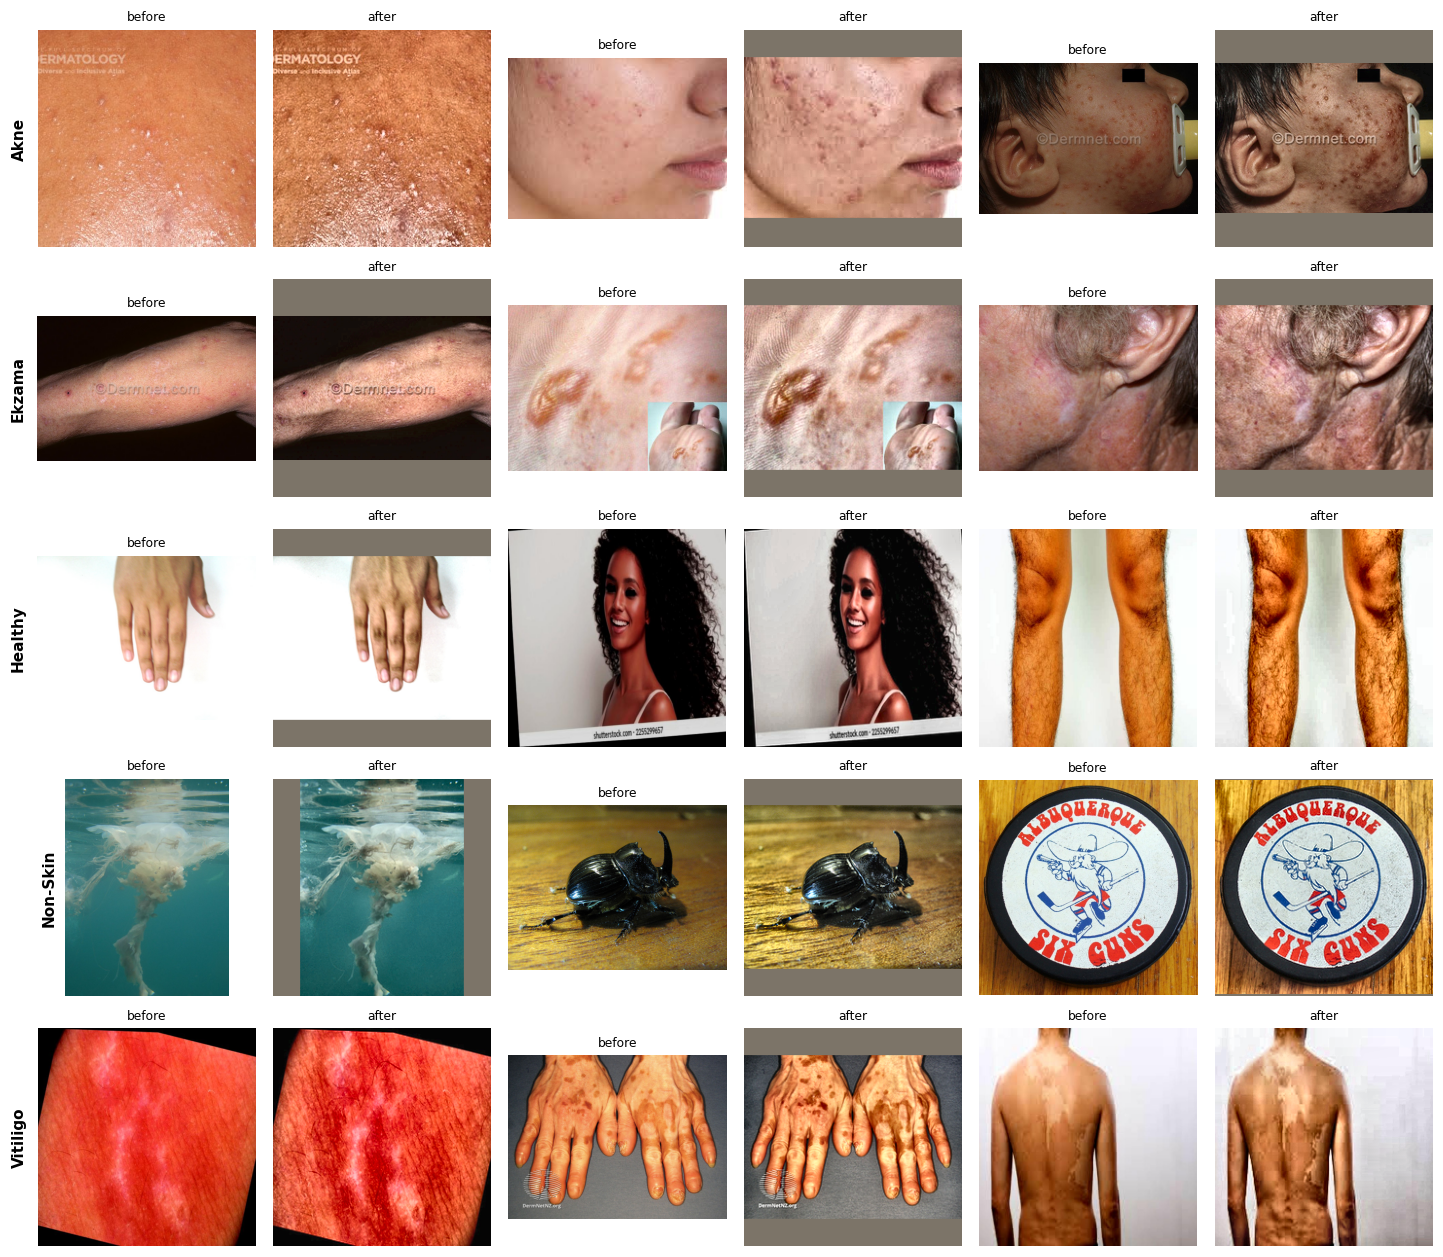

In [18]:
N_PER_CLASS = 3
fig, axes = plt.subplots(len(LABELS), N_PER_CLASS * 2, figsize=(2.2 * N_PER_CLASS * 2, 2.3 * len(LABELS)))
for r, label in enumerate(LABELS):
    picks = train_orig[train_orig["label"] == label].sample(N_PER_CLASS, random_state=SEED + 1)
    for k, (_, row) in enumerate(picks.iterrows()):
        with Image.open(row["path"]) as im:
            before = ImageOps.exif_transpose(im).convert("RGB")
        after = Image.open(row["out_path"])
        axes[r, 2 * k].imshow(before)
        axes[r, 2 * k].set_title("before", fontsize=8)
        axes[r, 2 * k + 1].imshow(after)
        axes[r, 2 * k + 1].set_title("after", fontsize=8)
        for a in axes[r, 2 * k:2 * k + 2]:
            a.axis("off")
    axes[r, 0].text(-0.05, 0.5, label, transform=axes[r, 0].transAxes, rotation=90,
                    va="center", ha="right", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

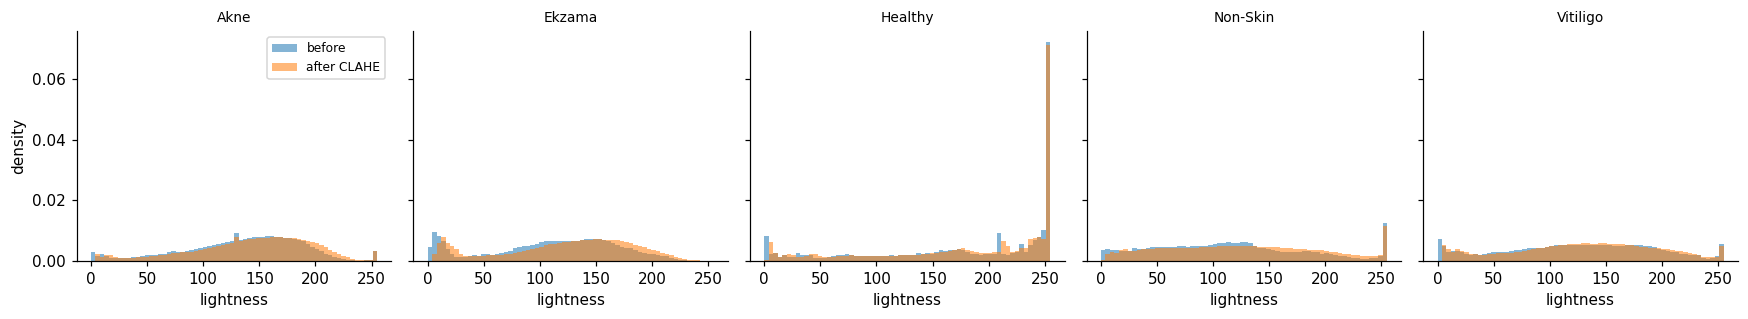

In [19]:
def lightness(img):
    return np.asarray(img.convert("L")).ravel()


fig, axes = plt.subplots(1, len(LABELS), figsize=(3.2 * len(LABELS), 3), sharey=True)
for ax, label in zip(axes, LABELS):
    sub = train_orig[train_orig["label"] == label].sample(50, random_state=SEED)
    before_px, after_px = [], []
    for _, row in sub.iterrows():
        with Image.open(row["path"]) as im:
            resized = resize_keep_aspect(ImageOps.exif_transpose(im).convert("RGB"), IMG_SIZE)
        before_px.append(lightness(resized))
        after_px.append(lightness(apply_clahe(resized)))
    ax.hist(np.concatenate(before_px), bins=64, range=(0, 255), density=True, alpha=0.55, label="before")
    ax.hist(np.concatenate(after_px), bins=64, range=(0, 255), density=True, alpha=0.55, label="after CLAHE")
    ax.set_title(label, fontsize=9)
    ax.set_xlabel("lightness")
axes[0].set_ylabel("density")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Output sizes found in a 300-image sample: {(224, 224)}

Train-set normalization stats (from preprocessing_meta.json):
     mean     std
R  0.6152  0.2664
G  0.5221  0.2559
B  0.4751  0.2668


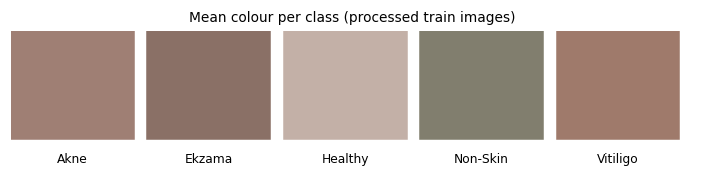

In [20]:
check = processed.sample(min(300, len(processed)), random_state=SEED)
shapes = {Image.open(p).size for p in check["out_path"]}
print("Output sizes found in a 300-image sample:", shapes)

print("\nTrain-set normalization stats (from preprocessing_meta.json):")
print(pd.DataFrame({"mean": meta["mean"], "std": meta["std"]}, index=["R", "G", "B"]).round(4).to_string())

mean_colors = {}
for label in LABELS:
    sub = train_orig[train_orig["label"] == label].sample(min(100, (train_orig["label"] == label).sum()), random_state=SEED)
    mean_colors[label] = np.mean([np.asarray(Image.open(p), dtype=np.float32).mean((0, 1)) for p in sub["out_path"]], axis=0)

fig, ax = plt.subplots(figsize=(1.6 * len(LABELS), 1.8))
for i, label in enumerate(LABELS):
    ax.add_patch(plt.Rectangle((i, 0), 0.9, 1, color=np.clip(mean_colors[label] / 255, 0, 1)))
    ax.text(i + 0.45, -0.12, label, ha="center", va="top", fontsize=8)
ax.set_xlim(0, len(LABELS))
ax.set_ylim(-0.4, 1)
ax.axis("off")
ax.set_title("Mean colour per class (processed train images)", fontsize=9)
plt.show()